In [ ]:
#Імпорт бібліотек
from google.colab import files
from google.colab import auth
from google.cloud import bigquery
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.dates as mdates
from scipy.stats import pearsonr, spearmanr
from scipy.stats import kruskal
from scipy.stats import mannwhitneyu
from statsmodels.stats.proportion import proportions_ztest
from matplotlib.colors import LinearSegmentedColormap

custom_cmap = LinearSegmentedColormap.from_list(
    "lavender_blue",
    ["#CFC3E6", "#A9A5D3", "#485979"]
)




In [ ]:
# Підключення до BigQuery
auth.authenticate_user()

client = bigquery.Client(project="data-analytics-mate")

# SQL-запит
query = """
WITH
  session_params AS (
    SELECT
      CAST(s.date AS DATE) AS session_date,
      s.ga_session_id AS session_id,
      CASE  # замінюємо значення '(not set)' на значення unknown
        WHEN continent = '(not set)' THEN 'unknown'
        ELSE continent
        END AS continent,
      sp.country AS country,
      device,
      CASE  # замінюємо значення '<Other>' на значення unknown
        WHEN browser = '<Other>' THEN 'unknown'
        ELSE browser
        END AS browser,
      REPLACE(REPLACE(mobile_model_name, '<', ''), '>', '')
        AS mobile_model_name,  # прибираємо зайві символи
      CASE  # замінюємо значення '<Other>' на значення unknown
        WHEN operating_system = '<Other>' THEN 'unknown'
        ELSE operating_system
        END AS operating_system,
      COALESCE(sp.language, 'Unknown')
        AS browser_language,  # замінюємо null на unknown
      channel AS traffic_channel,
      CASE  # замінюємо значення '(none)' на значення unknown
        WHEN sp.medium = '(none)' THEN 'unknown'
        ELSE REPLACE(REPLACE(sp.medium, '<', ''), '>', '')
        END AS traffic_source
    FROM `DA.session` s
    LEFT JOIN `DA.session_params` sp
      ON s.ga_session_id = sp.ga_session_id
  ),
  product_params AS (
    SELECT
      s.ga_session_id AS session_id,
      COALESCE(p.category, 'Unknown')
        AS category_name,  # замінюємо null на unknown
      COALESCE(p.name, 'Unknown')
        AS product_name,  # замінюємо null на unknown
      p.price,
      COALESCE(p.short_description, 'Unknown')
        AS product_description  # замінюємо null на unknown
    FROM `DA.session` s
    LEFT JOIN `DA.order` o
      ON s.ga_session_id = o.ga_session_id
    LEFT JOIN `DA.product` p
      ON o.item_id = p.item_id
  ),
  account_params AS (
    SELECT
      id AS account_id,
      a.is_unsubscribed,
      a.is_verified,
      acs.ga_session_id AS session_id
    FROM `DA.account` a
    LEFT JOIN `DA.account_session` acs
      ON a.id = acs.account_id
  )
SELECT
  s.session_date,
  s.session_id,
  s.continent,
  s.country,
  s.device,
  s.browser,
  s.mobile_model_name,
  s.operating_system,
  s.browser_language,
  s.traffic_source,
  s.traffic_channel,
  a.account_id,
  CASE  # замінюємо значення 1 та 0 на значення true та false та незаповнені значення на guest
    WHEN a.is_verified = 1 THEN 'true'
    WHEN a.is_verified = 0 THEN 'false'
    ELSE 'guest'
    END AS verified,
  CASE  # замінюємо значення 1 та 0 на значення true та false та незаповнені значення на guest
    WHEN a.is_unsubscribed = 1 THEN 'true'
    WHEN a.is_unsubscribed = 0 THEN 'false'
    ELSE 'guest'
    END AS unsubscribed,
  p.category_name,
  p.product_name,
  p.price AS product_price,
  p.product_description
FROM session_params s
LEFT JOIN product_params p
  ON s.session_id = p.session_id
LEFT JOIN account_params a
  ON s.session_id = a.session_id
  """

query_job = client.query(query)
results = query_job.result()



In [ ]:
# Створення DataFrame
df = results.to_dataframe()

In [ ]:
#Огляд DataFrame
df.head()

,session_date,session_id,continent,country,device,browser,mobile_model_name,operating_system,browser_language,traffic_source,traffic_channel,account_id,verified,unsubscribed,category_name,product_name,product_price,product_description
0,2020-11-01,5760483956,Americas,United States,desktop,Chrome,Safari,Macintosh,zh,Other,Paid Search,<NA>,guest,guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
1,2020-11-01,7115337200,Europe,United Kingdom,desktop,Chrome,Chrome,Web,en-us,organic,Organic Search,<NA>,guest,guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
2,2020-11-01,3978035233,Europe,Norway,mobile,Chrome,Other,Web,zh,unknown,Direct,<NA>,guest,guest,Tables & desks,RÅSKOG,189.0,"Trolley, 35x45x78 cm"
3,2020-11-01,9648986282,Africa,Nigeria,mobile,Chrome,Other,Android,es-es,unknown,Direct,<NA>,guest,guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"
4,2020-11-01,4393441533,Asia,China,desktop,Chrome,Chrome,Windows,en-us,unknown,Direct,<NA>,guest,guest,Bookcases & shelving units,VITTSJÖ,609.0,"Shelving unit with laptop table, 202x36x175 cm"


In [ ]:
#Перетворення дати на формат datetime64[ns]
df['session_date'] = pd.to_datetime(df['session_date'])

In [ ]:

df.to_csv('my_data.csv', index=False)
files.download('my_data.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#Перевірка пропущених значень
df.isnull().sum()

,0
session_date,0
session_id,0
continent,0
country,0
device,0
browser,0
mobile_model_name,0
operating_system,0
browser_language,0
traffic_source,0


In [ ]:
#Перевірка датафрейму на дублікати
df.duplicated().sum()

np.int64(0)

In [ ]:
#Перевіримо, чи немає зайвих пробілів у текстових колонках
df.select_dtypes(include='object').apply(
    lambda col: col.str.strip().ne(col).sum()
)

,0
continent,0
country,0
device,0
browser,0
mobile_model_name,0
operating_system,0
browser_language,0
traffic_source,0
traffic_channel,0
verified,0


In [ ]:
# Кількість рядків і колонок
print(f"Кількість рядків: {df.shape[0]}")
print(f"Кількість колонок: {df.shape[1]}")

# Типи даних
df.info()

# Кількість унікальних сесій
print("Унікальних сесій:", df["session_id"].nunique())

# Період дат
print("Перша дата:", df["session_date"].min())
print("Остання дата:", df["session_date"].max())

# Пропущені значення
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("\nКолонки з пропущеними значеннями:")
print(missing)

# Відсоток пропущених значень
print("\nВідсоток пропусків:")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False))

Кількість рядків: 349545
Кількість колонок: 18
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349545 entries, 0 to 349544
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   session_date         349545 non-null  datetime64[ns]
 1   session_id           349545 non-null  Int64         
 2   continent            349545 non-null  object        
 3   country              349545 non-null  object        
 4   device               349545 non-null  object        
 5   browser              349545 non-null  object        
 6   mobile_model_name    349545 non-null  object        
 7   operating_system     349545 non-null  object        
 8   browser_language     349545 non-null  object        
 9   traffic_source       349545 non-null  object        
 10  traffic_channel      349545 non-null  object        
 11  account_id           27945 non-null   Int64         
 12  verified             3495

In [ ]:
print("Розмір датафрейму:", df.shape)
print("Кількість унікальних сесій:", df['session_id'].nunique())
print("Кількість дублікатів рядків:", df.duplicated().sum())
print("Кількість дублікатів session_id:", df['session_id'].duplicated().sum())
print("Кількість пропусків:\n", df.isnull().sum())
print("Типи даних:\n", df.dtypes)

Розмір датафрейму: (349545, 18)
Кількість унікальних сесій: 349545
Кількість дублікатів рядків: 0
Кількість дублікатів session_id: 0
Кількість пропусків:
 session_date                0
session_id                  0
continent                   0
country                     0
device                      0
browser                     0
mobile_model_name           0
operating_system            0
browser_language            0
traffic_source              0
traffic_channel             0
account_id             321600
verified                    0
unsubscribed                0
category_name               0
product_name                0
product_price          316007
product_description         0
dtype: int64
Типи даних:
 session_date           datetime64[ns]
session_id                      Int64
continent                      object
country                        object
device                         object
browser                        object
mobile_model_name              object
operating_sys

## Опис Dataframe

У результаті виконання SQL-запиту та подальшої обробки даних у Python було створено датафрейм, який містить інформацію про сесії користувачів, їхні пристрої, джерела трафіку, зареєстровані акаунти та товари.

Датафрейм містить 349 545 рядків і 18 колонок. Кожен рядок відповідає запису про сесію з додатковою інформацією про користувача та товар, якщо такі дані доступні.

**Основні характеристики**

Кількість колонок: 18.

Числові колонки — 3

session_id — ідентифікатор сесії.

account_id — ідентифікатор зареєстрованого користувача.

product_price — ціна товару.

Категоріальні колонки — 14

continent — континент.

country — країна.

device — тип пристрою.

browser — браузер.

mobile_model_name — модель пристрою.

operating_system — операційна система.

browser_language — мова браузера.

traffic_source — джерело трафіку.

traffic_channel — канал трафіку.

verified — статус підтвердження email.

unsubscribed — статус підписки на розсилку.

category_name — категорія товару.

product_name — назва товару.

product_description — короткий опис товару.

Колонки типу datetime — 1

session_date — дата сесії.

Таким чином, датафрейм містить 3 числові колонки, 14 категоріальних і 1 колонку типу datetime.

**Період даних та унікальні сесії**

Загальна кількість рядків: 349 545.

Кількість унікальних сесій: 349 545.

Початок періоду: 1 листопада 2020 року.

Кінець періоду: 31 січня 2021 року.

Кількість унікальних сесій дорівнює кількості рядків. Це означає, що в отриманому датафреймі кожен session_id зустрічається лише один раз.

**Як було отримано дані за допомогою SQL**

Для створення датафрейму було використано SQL-запит із трьома CTE (Common Table Expressions), які допомогли підготувати дані з різних таблиць бази даних.

1. session_params

Цей блок об'єднує інформацію про сесії з таблицями параметрів сесій. Він формує дані про дату та ідентифікатор сесії, географію, пристрій, браузер, операційну систему, мову браузера та джерело трафіку.

Також у цьому блоці було стандартизовано деякі значення: наприклад, (not set) і <Other> замінено на unknown, а зайві символи видалено з назв моделей пристроїв.

2. product_params

Цей блок об'єднує таблиці сесій, замовлень і товарів. Завдяки цьому до кожної сесії можна додати інформацію про категорію, назву, ціну та короткий опис товару.

Для текстових полів, у яких значення були відсутні, використовувалася функція COALESCE, яка замінює NULL на Unknown.

3. account_params

Цей блок об'єднує інформацію про зареєстрованих користувачів та їхні сесії. Він дозволяє отримати ідентифікатор акаунта, статус підтвердження email і статус підписки на розсилку.

Після виконання SQL-запиту результат було отримано в Python за допомогою бібліотеки Pandas. Для цього результат запиту перетворили на датафрейм за допомогою методу to_dataframe().

**Пропущені значення**

Після перевірки датафрейму за допомогою df.info(), df.isnull().sum() та розрахунку відсотка пропусків було виявлено пропущені значення у двох колонках.

Колонка

account_id - 321 600 = 92,01%

product_price - 316 007 = 90,41%

В інших колонках пропущених значень немає.

Чому виникли пропуски?

account_id

Основна причина полягає в тому, що значна частина відвідувачів сайту не зареєстрована або не має пов'язаного з сесією акаунта. Оскільки ми використовували LEFT JOIN, сесії таких відвідувачів залишилися в датафреймі, але відповідний account_id не знайшовся.

Це очікувана ситуація, адже мета проєкту — аналізувати всі сесії, а не лише сесії зареєстрованих користувачів.

product_price

Пропуски виникли через те, що не для всіх сесій знайшлася пов'язана інформація про товар і його ціну. Це може бути пов'язано з тим, що користувач переглядав сайт, але не здійснив замовлення, або що для сесії не знайшлося відповідного запису в таблицях замовлень чи товарів.

**Додаткові спостереження**

Під час попередньої обробки даних було виконано такі дії:

Перетворено session_date на тип datetime64[ns], щоб надалі можна було аналізувати дані за датами та періодами.

Перевірено наявність дублікатів: df.duplicated().sum() повернув 0.

Перевірено унікальні значення в окремих категоріальних колонках.

Перевірено текстові поля на наявність порожніх рядків.

Стандартизовано деякі текстові значення та замінено частину NULL на Unknown.


# Головна мета проєкту
Зрозуміти, від чого залежать продажі інтернет-магазину, які фактори пов'язані з вищими доходами та де компанія має можливості для зростання.

**Для цього дослідимо п'ять основних напрямів:**
1. Географія продажів: де компанія заробляє найбільше?
2. Товари: які категорії приносять найбільший дохід?
3. Канали та пристрої: звідки приходять покупці та через які пристрої здійснюють покупки?
4. Динаміка продажів: як змінюється дохід у часі та чи є сезонні закономірності?
5. Поведінка користувачів: чи пов'язані реєстрація з продажами та кількістю сесій?

#Загальні метрики

In [ ]:
# Загальний дохід за весь період

total_revenue = df["product_price"].sum()

print(f"Загальний дохід: ${total_revenue:,.2f}")


Загальний дохід: $31,971,731.10


In [ ]:
# Загальна кількість сесій - наскільки активно користувачі відвідували сайт

total_sessions = df["session_id"].nunique()

print(f"Загальна кількість сесій: {total_sessions:,}")



Загальна кількість сесій: 349,545


In [ ]:
# Кількість замовлень - скільки замовлень було здійснено

total_sales = df["product_price"].count()

print(f"Кількість замовлень: {total_sales:,}")

Кількість замовлень: 33,538


In [ ]:
# Середній дохід на замовлення - Який дохід у середньому приносить одне замовлення

avg_product_price = df["product_price"].mean()

print(f"Середній дохід на замовлення: ${avg_product_price:.2f}")

Середній дохід на замовлення: $953.30


In [ ]:
# Частка продажів за країнами - Які країни формують найбільшу частину доходу

# Рахуємо загальний дохід для кожної країни
country_sales = df.groupby('country')['product_price'].sum().reset_index()

# Перейменовуємо колонки
country_sales.columns = ['country', 'total_revenue']

# Рахуємо частку кожної країни в загальному доході, %
country_sales['revenue_share'] = (
    country_sales['total_revenue'] / country_sales['total_revenue'].sum() * 100
).round(2)

# Сортуємо країни за доходом від найбільшого до найменшого
country_sales = country_sales.sort_values(
    by='total_revenue',
    ascending=False
)

# Виводимо топ-10 країн
display(country_sales.head(10))

,country,total_revenue,revenue_share
104,United States,13943553.9,43.61
43,India,2809762.0,8.79
18,Canada,2437921.0,7.63
103,United Kingdom,938317.9,2.93
33,France,710692.8,2.22
92,Spain,631546.7,1.98
35,Germany,599221.4,1.87
20,China,588329.6,1.84
96,Taiwan,552710.3,1.73
87,Singapore,456447.2,1.43


In [ ]:
# Частка продажів за категоріями - Які товари приносять найбільший дохід

category_sales = df.groupby("category_name")["product_price"].sum().reset_index()

category_sales.columns = ["category_name", "total_revenue"]

category_sales["revenue_share"] = (
    category_sales["total_revenue"] / category_sales["total_revenue"].sum() * 100
)

category_sales = category_sales.sort_values(
    by="total_revenue",
    ascending=False
)

category_sales["total_revenue"] = category_sales["total_revenue"].apply(
    lambda x: f"${x:,.2f}"
)

category_sales["revenue_share"] = category_sales["revenue_share"].apply(
    lambda x: f"{x:.2f}%"
)

# Виводимо топ-10 категорій
display(category_sales.head(10))



,category_name,total_revenue,revenue_share
12,Sofas & armchairs,"$8,388,254.50",26.24%
5,Chairs,"$6,147,748.80",19.23%
1,Beds,"$4,919,725.00",15.39%
2,Bookcases & shelving units,"$3,640,818.10",11.39%
3,Cabinets & cupboards,"$2,336,499.50",7.31%
9,Outdoor furniture,"$2,142,222.20",6.70%
13,Tables & desks,"$1,790,307.50",5.60%
6,Chests of drawers & drawer units,"$906,562.50",2.84%
0,Bar furniture,"$735,503.00",2.30%
7,Children's furniture,"$467,697.00",1.46%


In [ ]:
# Частка продажів за каналами - Які джерела трафіку пов'язані з найбільшим доходом

channel_sales = (
    df.groupby("traffic_channel")["product_price"]
    .sum()
    .reset_index()
)

channel_sales.columns = ["traffic_channel", "total_revenue"]

channel_sales["revenue_share"] = (
    channel_sales["total_revenue"]
    / channel_sales["total_revenue"].sum()
    * 100
)

channel_sales = channel_sales.sort_values(
    by="total_revenue",
    ascending=False
)

channel_sales_display = channel_sales.copy()

channel_sales_display["total_revenue"] = (
    channel_sales_display["total_revenue"]
    .map(lambda x: f"${x:,.2f}")
)

channel_sales_display["revenue_share"] = (
    channel_sales_display["revenue_share"]
    .map(lambda x: f"{x:.2f}%")
)

display(channel_sales_display)


,traffic_channel,total_revenue,revenue_share
1,Organic Search,"$11,433,151.60",35.76%
2,Paid Search,"$8,511,049.40",26.62%
0,Direct,"$7,494,923.40",23.44%
3,Social Search,"$2,532,105.70",7.92%
4,Undefined,"$2,000,501.00",6.26%


In [ ]:
# Частка продажів за пристроями - Які типи пристроїв формують найбільшу частину доходу

device_sales = (
    df.groupby("device")["product_price"]
    .sum()
    .reset_index()
)

device_sales.columns = ["device", "total_revenue"]

device_sales["revenue_share"] = (
    device_sales["total_revenue"]
    / device_sales["total_revenue"].sum()
    * 100
)

device_sales = device_sales.sort_values(
    by="total_revenue",
    ascending=False
)

device_sales_display = device_sales.copy()

device_sales_display["total_revenue"] = (
    device_sales_display["total_revenue"]
    .map(lambda x: f"${x:,.2f}")
)

device_sales_display["revenue_share"] = (
    device_sales_display["revenue_share"]
    .map(lambda x: f"{x:.2f}%")
)

display(device_sales_display)


,device,total_revenue,revenue_share
0,desktop,"$18,864,039.00",59.00%
1,mobile,"$12,384,225.80",38.73%
2,tablet,"$723,466.30",2.26%


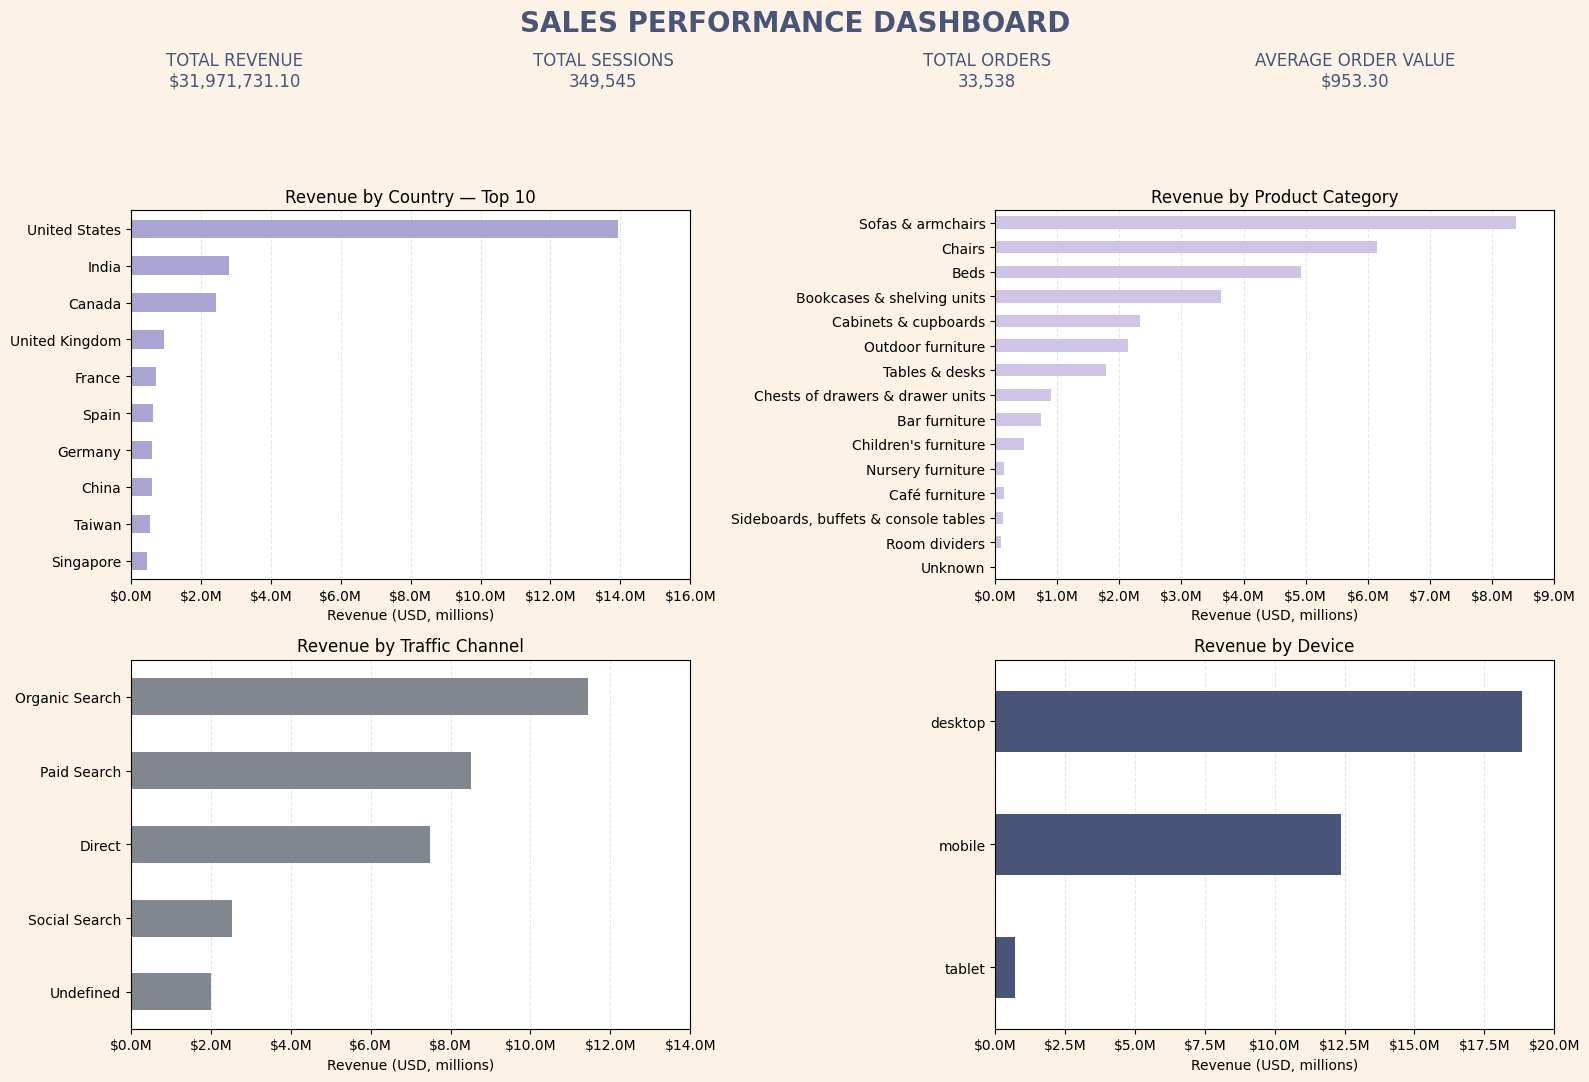

In [ ]:
# Загальний дашборд з основними метриками

PALETTE = [
    "#CFC3E6",
    "#A9A5D3",
    "#81878E",
    "#485579"
]

BG_COLOR = "#FCF3E6"

# Основні метрики
total_revenue = df["product_price"].sum()
total_sessions = df["session_id"].nunique()
total_orders = df["product_price"].count()
avg_order = df["product_price"].mean()

# Готуємо дані для графіків
country_sales = df.groupby("country")["product_price"].sum()
category_sales = df.groupby("category_name")["product_price"].sum()
channel_sales = df.groupby("traffic_channel")["product_price"].sum()
device_sales = df.groupby("device")["product_price"].sum()

# Створюємо дашборд
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.patch.set_facecolor(BG_COLOR)

fig.suptitle(
    "SALES PERFORMANCE DASHBOARD",
    fontsize=20,
    fontweight="bold",
    color=PALETTE[3]
)

# Картки з основними метриками
fig.text(0.15, 0.91, f"TOTAL REVENUE\n${total_revenue:,.2f}",
         ha="center", fontsize=12, color=PALETTE[3])

fig.text(0.38, 0.91, f"TOTAL SESSIONS\n{total_sessions:,}",
         ha="center", fontsize=12, color=PALETTE[3])

fig.text(0.62, 0.91, f"TOTAL ORDERS\n{total_orders:,}",
         ha="center", fontsize=12, color=PALETTE[3])

fig.text(0.85, 0.91, f"AVERAGE ORDER VALUE\n${avg_order:,.2f}",
         ha="center", fontsize=12, color=PALETTE[3])


# 1. Revenue by Country
country_sales.sort_values().tail(10).plot(
    kind="barh",
    ax=axes[0, 0],
    color=PALETTE[1]
)

axes[0, 0].set_title("Revenue by Country — Top 10")
axes[0, 0].set_xlabel("Revenue (USD)")
axes[0, 0].set_ylabel("")


# 2. Revenue by Category
category_sales.sort_values().plot(
    kind="barh",
    ax=axes[0, 1],
    color=PALETTE[0]
)

axes[0, 1].set_title("Revenue by Product Category")
axes[0, 1].set_xlabel("Revenue (USD)")
axes[0, 1].set_ylabel("")


# 3. Revenue by Traffic Channel
channel_sales.sort_values().plot(
    kind="barh",
    ax=axes[1, 0],
    color=PALETTE[2]
)

axes[1, 0].set_title("Revenue by Traffic Channel")
axes[1, 0].set_xlabel("Revenue (USD)")
axes[1, 0].set_ylabel("")


# 4. Revenue by Device
device_sales.sort_values().plot(
    kind="barh",
    ax=axes[1, 1],
    color=PALETTE[3]
)

axes[1, 1].set_title("Revenue by Device")
axes[1, 1].set_xlabel("Revenue (USD)")
axes[1, 1].set_ylabel("")


# Оформлення графіків
for ax in axes.flat:
    ax.set_facecolor("white")
    ax.ticklabel_format(axis="x", style="plain")
    ax.grid(axis="x", linestyle="--", alpha=0.3)
    ax.set_axisbelow(True)


# Відображаємо дохід у мільйонах доларів
for ax in axes.flat:
    ax.set_xlabel("Revenue (USD, millions)")
    ax.set_xticks(ax.get_xticks())
    ax.set_xticklabels(
        [f"${x / 1_000_000:.1f}M" for x in ax.get_xticks()]
    )

plt.tight_layout(rect=[0, 0, 1, 0.87])
plt.show()



##  Загальні висновки по основним метрикам

За результатами первинного аналізу даних загальний дохід від продажів становить **31,97 млн**, а загальна кількість замовлень — **33 538**. Зафіксовано **349 545 сесій** на сайті, а середній дохід на одне замовлення становить **953,30**.

Аналіз географічного розподілу доходу показав, що найбільшу частку продажів забезпечують **США — близько 43,61% загального доходу**. Наступними за обсягом доходу є Індія та Канада. Це свідчить про значну роль американського ринку в загальних результатах компанії.

За категоріями товарів лідирують **Sofas & armchairs (дивани та крісла)**, які формують 26,24% доходу, а також Chairs (стільці) — 19,23% і Beds (ліжка) — 15,39%. Ці три категорії разом забезпечують понад 60% загального доходу.

Серед каналів залучення найбільший дохід приносить **Organic Search — 35,76%**, за ним ідуть Paid Search — 26,62% та Direct — 23,44%. Це вказує на важливу роль органічного пошуку, платної реклами та прямих переходів у формуванні продажів.

Аналіз пристроїв показав, що найбільша частка доходу припадає на **desktop — 59,00%**, тоді як mobile забезпечує 38,73%, а tablet — 2,26%. Отже, настільні комп'ютери є основним джерелом доходу серед проаналізованих типів пристроїв, проте мобільний сегмент також має суттєве значення.



#Динаміка та порівняння

### Географічні відмінності в асортименті - порівняємо п'ять країн із найбільшим доходом і з'ясуємо, які категорії товарів популярні в кожній із них.

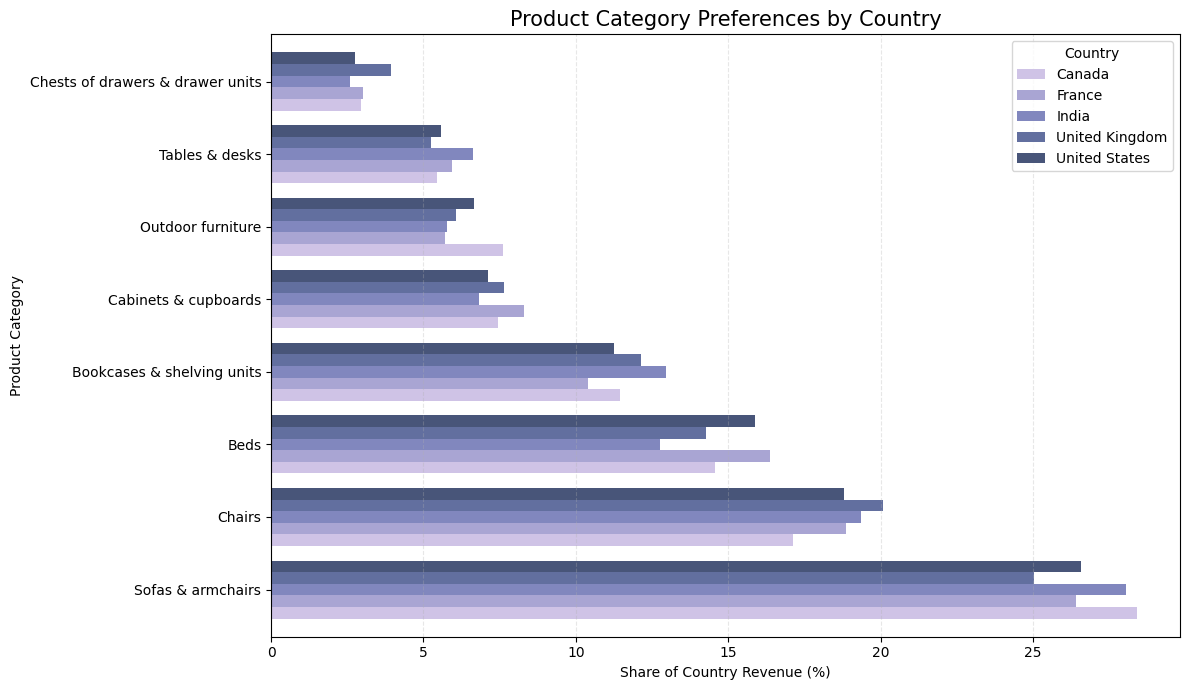

In [ ]:

# 1. Знаходимо 5 країн із найбільшим доходом
top_countries = (
    df.groupby("country")["product_price"]
    .sum()
    .nlargest(5)
    .index
)

# 2. Рахуємо дохід за країнами та категоріями
geo_sales = df[df["country"].isin(top_countries)].groupby(
    ["country", "category_name"]
)["product_price"].sum().reset_index()

# 3. Рахуємо частку кожної категорії в доході країни
geo_sales["share"] = (
    geo_sales["product_price"]
    / geo_sales.groupby("country")["product_price"].transform("sum")
    * 100
)

# 4. Створюємо таблицю для порівняння
geo_pivot = geo_sales.pivot(
    index="category_name",
    columns="country",
    values="share"
).fillna(0)

# Залишаємо 8 категорій із найбільшою сумарною часткою
top_categories = geo_pivot.sum(axis=1).nlargest(8).index
geo_pivot = geo_pivot.loc[top_categories]

# 5. Будуємо графік
colors = ["#CFC3E6", "#A9A5D3", "#8187BE", "#626F9F", "#485579"]

ax = geo_pivot.plot(
    kind="barh",
    figsize=(12, 7),
    color=colors,
    width=0.8
)

ax.set_title("Product Category Preferences by Country", fontsize=15)
ax.set_xlabel("Share of Country Revenue (%)")
ax.set_ylabel("Product Category")
ax.legend(title="Country")
ax.grid(axis="x", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

**Висновок**

Аналіз показав, що в п'яти країнах із найбільшим доходом спостерігаються схожі товарні вподобання. Найбільшу частку продажів у кожній країні формують дивани та крісла (*Sofas & armchairs*), стільці (*Chairs*) і ліжка (*Beds*).

Це підтверджує попередні розрахунки: саме ці категорії, разом із книжковими шафами та стелажами (*Bookcases & shelving units*) і шафами (*Cabinets & cupboards*), входять до п'ятірки лідерів за загальним доходом.

Водночас частка окремих категорій відрізняється залежно від країни. Це свідчить про можливі регіональні особливості попиту, які варто враховувати під час планування асортименту та маркетингових кампаній.

###Продажі за континентами

Sales by continent, millions:
continent
Americas    17.67
Asia         7.60
Europe       5.93
Oceania      0.37
Africa       0.33
unknown      0.07
Name: product_price, dtype: float64


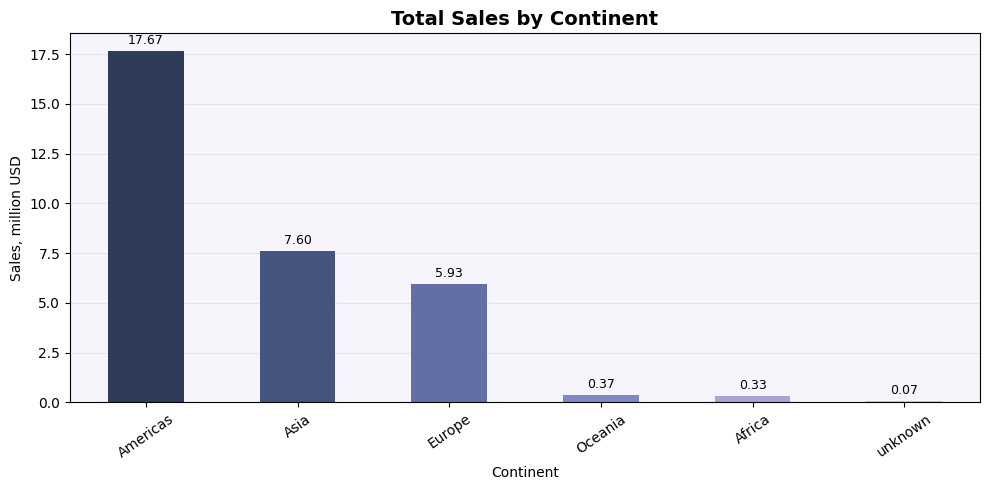

In [ ]:
sales_by_continent_mln = (
    df.groupby("continent")["product_price"]
    .sum()
    .div(1_000_000)
    .sort_values(ascending=False)
)

print("Sales by continent, millions:")
print(sales_by_continent_mln.round(2))

palette = [
    "#2E3B5B",
    "#465580",
    "#626FA5",
    "#8289C2",
    "#A8A5D3",
    "#CEC4E5"
]

colors = palette[:len(sales_by_continent_mln)]

# Build the chart
fig, ax = plt.subplots(figsize=(10, 5))

sales_by_continent_mln.plot(
    kind="bar",
    color=colors,
    ax=ax
)

ax.set_title(
    "Total Sales by Continent",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Continent")
ax.set_ylabel("Sales, million USD")

ax.tick_params(axis="x", rotation=35)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

ax.set_facecolor("#F7F5FC")
fig.patch.set_facecolor("#FFFFFF")
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


**Опис результатів**

Найбільша сума продажів за досліджуваний період припадає на Америку — 17,67 млн. Далі йдуть Азія з 7,60 млн та Європа з 5,93 млн. В інших регіонах обсяги продажів значно нижчі: в Океанії — 0,37 млн, в Африці — 0,33 млн. На записи з невизначеним континентом припадає близько 0,07 млн продажів.

Таким чином, основна частина продажів зосереджена в трьох регіонах: Америці, Азії та Європі.

### Щоденна динаміка продажів - як змінюється дохід із часом

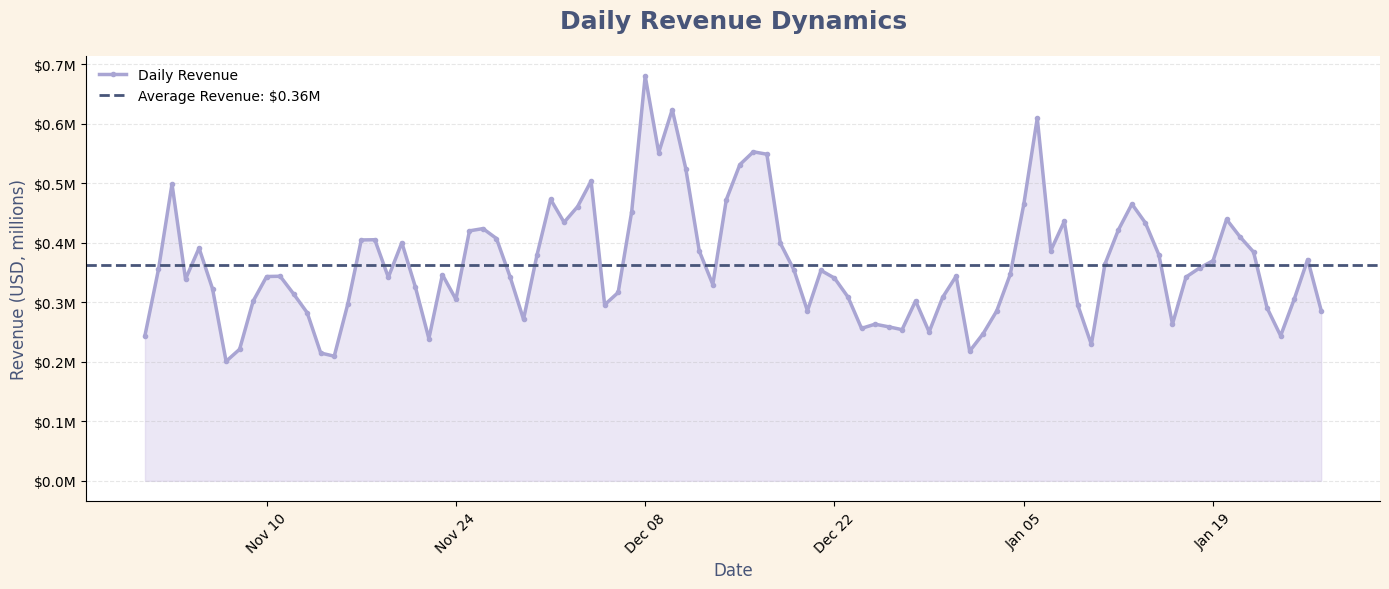

In [ ]:
BG_COLOR = "#FCF3E6"
LAVENDER = "#A9A5D3"
LIGHT_LAVENDER = "#CFC3E6"
DARK_BLUE = "#485579"

# Розрахунок щоденного доходу в мільйонах доларів
daily_revenue = (
    df.groupby(df['session_date'].dt.date)['product_price']
    .sum()
    / 1_000_000
)

# Сортуємо дати та виключаємо останні 4 дні
daily_revenue = daily_revenue.sort_index()
daily_revenue = daily_revenue.iloc[:-4]

# Розрахунок середнього щоденного доходу
average_revenue = daily_revenue.mean()

# Створення графіка
fig, ax = plt.subplots(figsize=(14, 6))

fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor("#FFFFFF")

# Лінія щоденного доходу
ax.plot(
    daily_revenue.index,
    daily_revenue.values,
    color=LAVENDER,
    linewidth=2.5,
    marker='o',
    markersize=3,
    label='Daily Revenue'
)

# Заповнення області під графіком
ax.fill_between(
    daily_revenue.index,
    daily_revenue.values,
    color=LIGHT_LAVENDER,
    alpha=0.4
)

# Лінія середнього доходу
ax.axhline(
    average_revenue,
    color=DARK_BLUE,
    linestyle='--',
    linewidth=2,
    label=f'Average Revenue: ${average_revenue:.2f}M'
)

# Заголовок та підписи осей
ax.set_title(
    'Daily Revenue Dynamics',
    fontsize=18,
    fontweight='bold',
    color=DARK_BLUE,
    pad=20
)

ax.set_xlabel('Date', fontsize=12, color=DARK_BLUE)
ax.set_ylabel('Revenue (USD, millions)', fontsize=12, color=DARK_BLUE)

# Форматування осі Y
ax.yaxis.set_major_formatter(
    FuncFormatter(lambda x, _: f'${x:.1f}M')
)

# Форматування дат
ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))

plt.xticks(rotation=45)

# Сітка та легенда
ax.grid(axis='y', linestyle='--', alpha=0.3)
ax.legend(frameon=False, loc='upper left')

# Прибираємо зайві межі
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

### Висновок: щоденна динаміка продажів

Аналіз щоденного доходу показав, що протягом досліджуваного періоду продажі характеризуються значними коливаннями. Дохід змінюється від дня до дня, без чіткої стабільної тенденції до зростання або зниження.

- **Середній щоденний дохід** становить приблизно 0,36 млн.
- **Найбільший пік доходу** спостерігається на початку грудня, коли щоденний дохід наближається до 0,7 млн.
- Протягом окремих періодів дохід перевищує середній рівень, проте є й дні зі значно нижчими показниками — близько 0,2–0,3 млн.

**Обмеження даних:** останні чотири дні досліджуваного періоду не включено до графіка та розрахунку середнього доходу, оскільки дані про продажі за ці дні відсутні. Тому їх не можна інтерпретувати як дні з нульовими продажами.


##Щоденний розподіл сесій

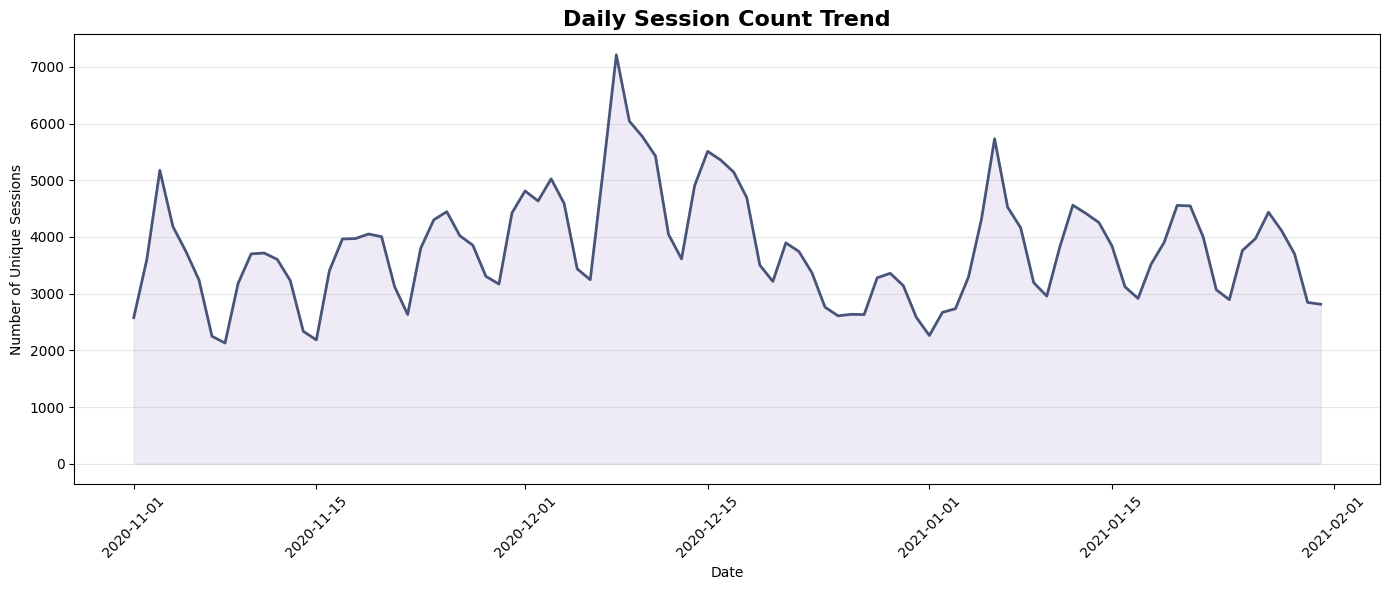

In [ ]:

daily_sessions = (
    df.groupby(df["session_date"].dt.date)["session_id"]
    .nunique()
    .sort_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    x=daily_sessions.index,
    y=daily_sessions.values,
    color=PALETTE[3],
    linewidth=2
)

plt.fill_between(
    daily_sessions.index,
    daily_sessions.values,
    color=PALETTE[0],
    alpha=0.35
)

plt.title(
    "Daily Session Count Trend",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Number of Unique Sessions")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

Найбільший пік — приблизно на початку грудня, понад 7 000 сесій.
Кількість сесій помітно коливається: є регулярні підйоми та спади.
На початку січня також є значний пік — приблизно 5 700 сесій.
Візуально немає стабільного зростання чи падіння протягом усього періоду.

##Кількість сесій за кожен день тижня

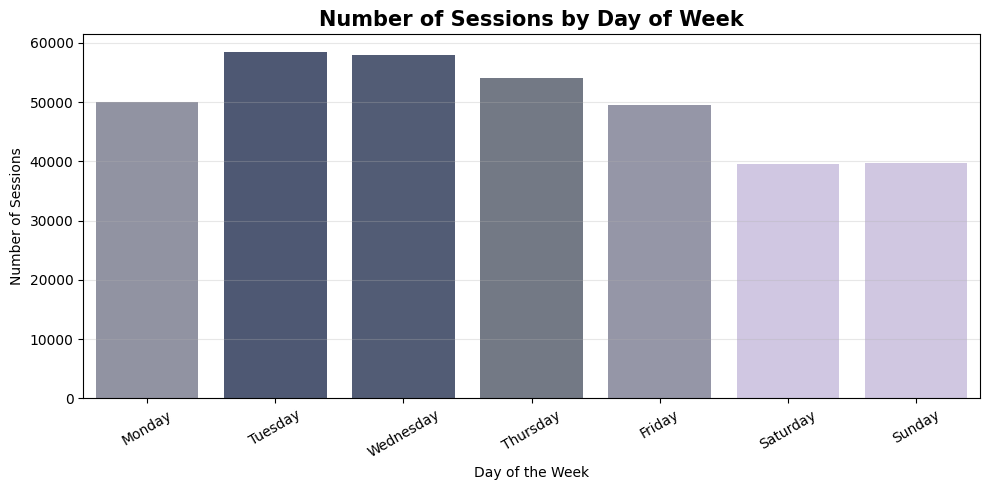

In [ ]:
df['day_of_week'] = df['session_date'].dt.day_name()

# Count unique sessions by weekday
sessions_by_weekday = (
    df.groupby('day_of_week')['session_id']
    .nunique()
    .reindex([
        'Monday', 'Tuesday', 'Wednesday',
        'Thursday', 'Friday', 'Saturday', 'Sunday'
    ])
)

# Visualization

# Preserve the original order of weekdays
values = sessions_by_weekday

# Normalize values so the color corresponds to the number of sessions
norm = plt.Normalize(values.min(), values.max())

cmap = sns.blend_palette(PALETTE, as_cmap=True)
colors = [cmap(norm(value)) for value in values]

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=values.index,
    y=values.values,
    hue=values.index,
    palette=colors,
    legend=False
)

plt.title(
    'Number of Sessions by Day of Week',
    fontsize=15,
    fontweight='bold'
)
plt.xlabel('Day of the Week')
plt.ylabel('Number of Sessions')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()



**Висновок.** Найбільша кількість унікальних сесій припадає на вівторок (близько 58,5 тис.) і середу (близько 58 тис.). Найнижча активність спостерігається у вихідні — суботу та неділю (приблизно по 39 тис. сесій). Загалом користувачі активніші в будні, ніж у вихідні.

###Середній денний дохід за групами користувачів - чи відрізняються групи за показниками продажів

In [ ]:
# Групуємо дані за статусом верифікації
user_summary = df.groupby('verified').agg(
    Revenue=('product_price', 'sum'),
    Sessions=('session_id', 'nunique')
)

# Розраховуємо середній денний дохід
user_summary['Average daily revenue'] = (
    user_summary['Revenue'] / 92
)

# Розраховуємо середній дохід на одну сесію
user_summary['Revenue per session'] = (
    user_summary['Revenue'] / user_summary['Sessions']
)

user_summary['Revenue'] = (
    user_summary['Revenue'] / 1_000_000
).round(2)

user_summary['Average daily revenue'] = (
    user_summary['Average daily revenue'] / 1_000_000
).round(3)

user_summary['Revenue per session'] = (
    user_summary['Revenue per session']
).round(2)

display(user_summary)



,Revenue,Sessions,Average daily revenue,Revenue per session
verified,,,,
false,0.72,7909,0.008,90.59
guest,29.39,321600,0.319,91.38
true,1.87,20036,0.020,93.13


Висновок: середній денний дохід за групами користувачів

Аналіз показав, що найбільший дохід генерують користувачі зі статусом guest — 29,39 млн доларів, а середній денний дохід цієї групи становить приблизно 319 тис. доларів. Це значно більше, ніж у верифікованих користувачів (true), дохід яких становить 1,87 млн доларів, та неверифікованих користувачів (false) — 0,72 млн доларів.

Водночас середній дохід на одну сесію в усіх трьох групах є досить близьким:

guest — 91,38 долара;

true — 93,13 долара;

false — 90,59 долара.

Отже, основна відмінність між групами полягає в загальному обсязі доходу, а не в доході на одну сесію. Група guest забезпечує найбільшу частку доходу завдяки значно більшій кількості сесій. При цьому верифіковані користувачі мають дещо вищий середній дохід на сесію, але їхня кількість значно менша.

Важливо враховувати, що категорія guest містить не лише користувачів без верифікації, а й записи, у яких статус був відсутній після об'єднання таблиць і був замінений на guest. Тому неможливо однозначно стверджувати, що всі ці сесії належать саме неавторизованим користувачам.

#Розрахунок ефективності каналів трафіку

In [ ]:
# Розраховуємо показники для кожного каналу
channel_summary = df.groupby('traffic_channel').agg(
    Revenue=('product_price', 'sum'),
    Sessions=('session_id', 'nunique')
)

# Дохід на одну сесію
channel_summary['Revenue per Session'] = (
    channel_summary['Revenue'] / channel_summary['Sessions']
)

# Переводимо дохід у мільйони доларів
channel_summary['Revenue'] = (
    channel_summary['Revenue'] / 1_000_000
).round(2)

# Форматуємо дохід на одну сесію
channel_summary['Revenue per Session'] = (
    channel_summary['Revenue per Session']
).round(2)

# Сортуємо за загальним доходом
channel_summary = channel_summary.sort_values(
    'Revenue', ascending=False
)

# Виводимо таблицю
display(
    channel_summary.style
    .format({
        'Revenue': '${:.2f}M',
        'Sessions': '{:,.0f}',
        'Revenue per Session': '${:.2f}'
    })
    .background_gradient(
        subset=['Revenue'],
        cmap='Purples'
    )
)


,Revenue,Sessions,Revenue per Session
traffic_channel,,,
Organic Search,$11.43M,"124,425",$91.89
Paid Search,$8.51M,"94,341",$90.22
Direct,$7.49M,"81,382",$92.10
Social Search,$2.53M,"27,914",$90.71
Undefined,$2.00M,"21,483",$93.12


###Розрахунок відсотку загального доходу, який  припадає на кожен канал

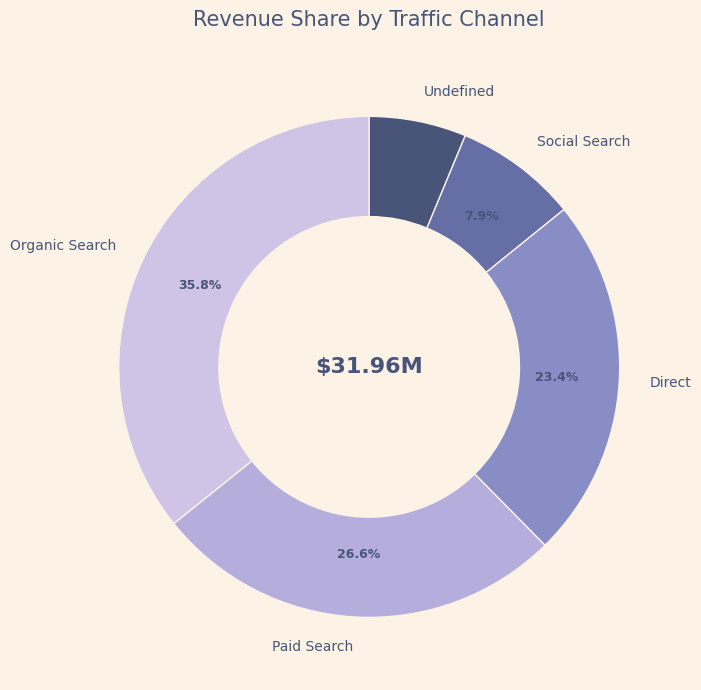

In [ ]:

BG_COLOR = "#FCF3E6"
colors = ["#CFC3E6", "#B5AEDC", "#898DC5", "#656FA5", "#485579"]

# Дані про дохід
revenue = channel_summary["Revenue"]

# Створюємо діаграму
fig, ax = plt.subplots(figsize=(10, 7))

fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

wedges, texts, autotexts = ax.pie(
    revenue,
    labels=revenue.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.75,
    labeldistance=1.12,
    wedgeprops={"width": 0.4, "edgecolor": BG_COLOR},
    textprops={"color": "#485579", "fontsize": 10}
)

# Оформлюємо відсотки
for text in autotexts:
    text.set_fontsize(9)
    text.set_fontweight("bold")
    text.set_color("#485579")

# Додаємо загальний дохід у центр
ax.text(
    0, 0,
    f"${revenue.sum():.2f}M",
    ha="center",
    va="center",
    fontsize=16,
    fontweight="bold",
    color="#485579"
)

ax.set_title(
    "Revenue Share by Traffic Channel",
    fontsize=15,
    color="#485579",
    pad=20
)

plt.tight_layout()
plt.show()

### Висновок

Аналіз показав, що **Organic Search є найефективнішим каналом за обсягом залученого трафіку та загальним доходом**. Він забезпечує 124 425 сесій і приносить $11,43 млн, що становить 35,8% загального доходу.

Важливо, що органічний трафік надходить із неоплачених результатів пошуку, тому зазвичай потребує менших прямих витрат на залучення користувачів, ніж платна реклама. Це робить його перспективним напрямом для подальшого розвитку.

**Рекомендація:** продовжувати інвестувати в SEO — покращувати позиції сайту в пошуковій видачі, оптимізувати сторінки товарів і розвивати корисний контент. Це допоможе залучати більше користувачів без пропорційного збільшення витрат на рекламу.

Paid Search і Direct також залишаються важливими каналами, забезпечуючи відповідно $8,51 млн і $7,49 млн доходу. Їхню ефективність варто продовжувати відстежувати, водночас **зробивши розвиток органічного трафіку одним із пріоритетів стратегії залучення користувачів**.

Окремо варто перевірити канал Undefined, на який припадає $2,00 млн доходу, щоб визначити джерела цього трафіку та покращити якість аналітики.

### Частка сесій за типом пристрою

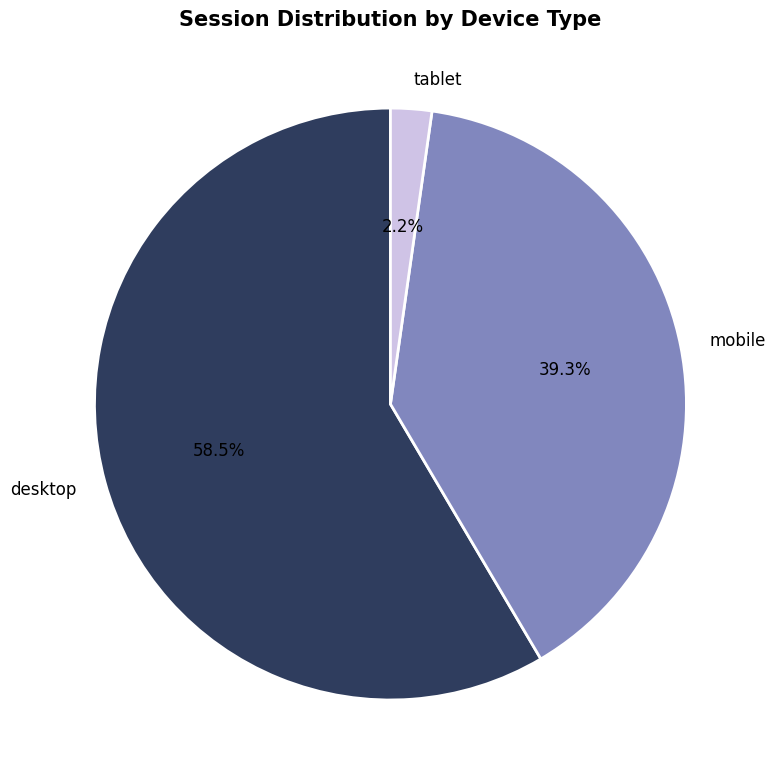

,Number of Sessions,"Share, %"
device,,
desktop,204429,58.48
mobile,137267,39.27
tablet,7849,2.25


In [ ]:
device_counts = df["device"].value_counts()


plt.figure(figsize=(8, 8))

colors = ["#2F3D5E", "#8187BE", "#CFC3E6"]

plt.pie(
    device_counts,
    labels=device_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12}
)

plt.title(
    "Session Distribution by Device Type",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

device_summary = device_counts.to_frame(name="Number of Sessions")

device_summary["Share, %"] = (
    device_summary["Number of Sessions"]
    / device_summary["Number of Sessions"].sum() * 100
)

display(device_summary.round(2))

**Висновок.** Найбільша частка сесій припадає на комп’ютери (desktop) — 58,48%. Мобільні пристрої (mobile) займають 39,27%, а планшети (tablet) — лише 2,25%. Отже, більшість користувачів відвідують сайт із комп’ютерів, але мобільний трафік також становить значну частку.

### Кількість сесій за країнами та пристроями

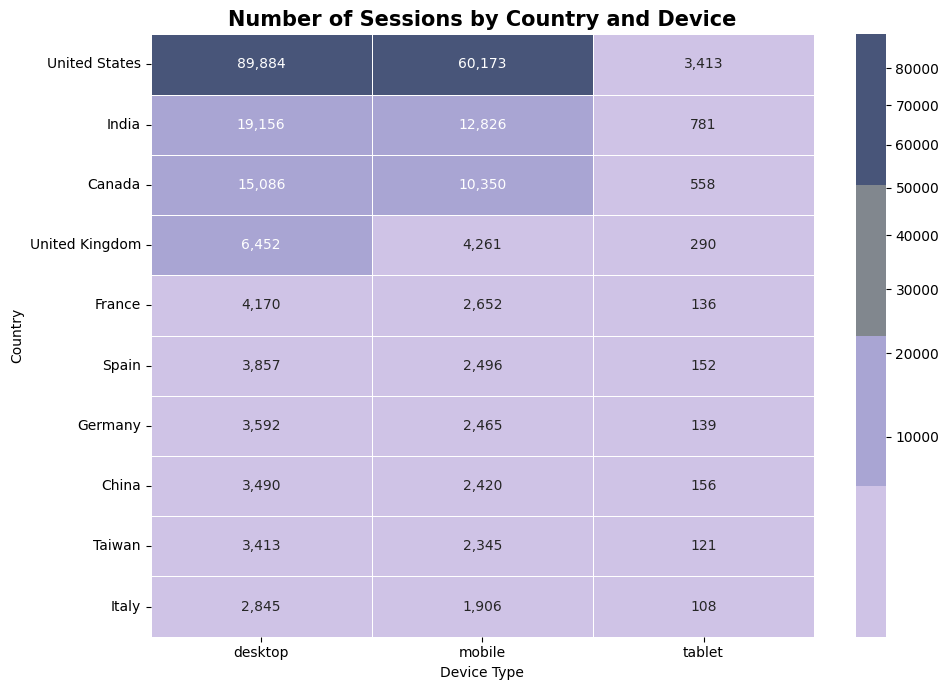

In [ ]:
heatmap_data = df.pivot_table(
    index="country",
    columns="device",
    values="session_id",
    aggfunc="nunique",
    fill_value=0
)

# Обираємо 10 країн із найбільшою кількістю сесій
top_countries = df["country"].value_counts().head(10).index

heatmap_data = heatmap_data.loc[
    heatmap_data.index.isin(top_countries)
]

# Сортуємо країни за загальною кількістю сесій
heatmap_data = heatmap_data.loc[
    heatmap_data.sum(axis=1).sort_values(ascending=False).index
]

# Створюємо власну кольорову палітру
custom_cmap = sns.color_palette(
    PALETTE,
    as_cmap=True
)

# Будуємо теплову карту
plt.figure(figsize=(10, 7))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=",",
    cmap=custom_cmap,
    linewidths=0.5,
    linecolor="white",
    norm=plt.matplotlib.colors.PowerNorm(gamma=0.5)
)

plt.title(
    "Number of Sessions by Country and Device",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Device Type")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

**Висновок.**

Найбільша кількість сесій зафіксована у США на всіх типах пристроїв, особливо на комп'ютерах (desktop) — 89 884 сесії. Друге місце посідає Індія, за нею — Канада. У всіх десяти країнах комп'ютери є найпопулярнішим типом пристрою, мобільні пристрої посідають друге місце, а планшети мають найменшу кількість сесій.

Ці результати допомагають визначити країни з найбільшою активністю користувачів і зрозуміти, які пристрої вони використовують найчастіше.

###Проаналізуємо кількість сесій за різними каналами трафіку та дізнаємося чи є статистично значущі відмінності між групами?  

In [ ]:
#Підготуємо дані для порівняння каналів
# Кількість сесій за кожен день у кожному каналі
sessions_by_channel = df.groupby(
    ['session_date', 'traffic_channel']
)['session_id'].nunique().reset_index()

# Перетворюємо таблицю: рядки — дні, стовпці — канали
sessions_pivot = sessions_by_channel.pivot(
    index='session_date',
    columns='traffic_channel',
    values='session_id'
).fillna(0)

display(sessions_pivot.head())

traffic_channel,Direct,Organic Search,Paid Search,Social Search,Undefined
session_date,,,,,
2020-11-01,608,920,706,214,128
2020-11-02,810,1242,970,315,262
2020-11-03,1216,1871,1367,392,327
2020-11-04,935,1425,1145,368,311
2020-11-05,845,1293,917,346,342


In [ ]:
#Перевіримо, чи є відмінності між каналами використаємо тест Краскела — Волліса


# Створюємо список зі значеннями для кожного каналу
channels = [
    sessions_pivot[column].values
    for column in sessions_pivot.columns
]

# Проводимо статистичний тест
statistic, p_value = kruskal(*channels)

print(f"Kruskal-Wallis statistic: {statistic:.3f}")
print(f"p-value: {p_value:}")

if p_value < 0.05:
    print("Є статистично значущі відмінності між каналами.")
else:
    print("Статистично значущих відмінностей не виявлено.")

Kruskal-Wallis statistic: 368.981
p-value: 1.397036102599359e-78
Є статистично значущі відмінності між каналами.


Аналіз виявив статистично значущі відмінності в кількості щоденних сесій між каналами трафіку (тест Краскела — Волліса, p < 0,05). Це означає, що розподіли кількості сесій у каналах відрізняються.

##Аналіз відмінностей у  продажі зареєстрованих і незареєстрованих користувачів

In [ ]:
#Створимо дві вибірки
# Залишаємо лише верифікованих і неверифікованих користувачів
users_df = df[df['verified'].isin(['true', 'false'])].copy()

# Перевіряємо кількість записів у кожній групі
print(users_df['verified'].value_counts())

verified
true     20036
false     7909
Name: count, dtype: int64


In [ ]:
#Порівняємо кількість сесій і дохід
user_summary = users_df.groupby('verified').agg(
    Revenue=('product_price', 'sum'),
    Sessions=('session_id', 'nunique')
)

display(user_summary)

,Revenue,Sessions
verified,,
false,716501.1,7909
true,1866017.4,20036


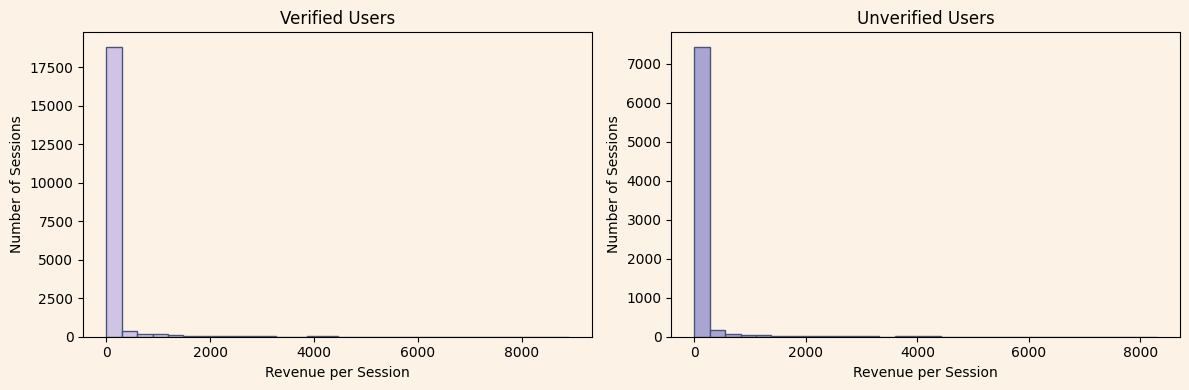

In [ ]:
#перевіримо розподіл і викиди


# Відокремлюємо дохід за сесіями для кожної групи
true_revenue = users_df[users_df['verified'] == 'true'].groupby(
    'session_id'
)['product_price'].sum()

false_revenue = users_df[users_df['verified'] == 'false'].groupby(
    'session_id'
)['product_price'].sum()

# Будуємо графіки розподілу
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(true_revenue, bins=30, color=LIGHT_LAVENDER, edgecolor=DARK_BLUE)
axes[0].set_title('Verified Users')
axes[0].set_xlabel('Revenue per Session')
axes[0].set_ylabel('Number of Sessions')

axes[1].hist(false_revenue, bins=30, color=LAVENDER, edgecolor=DARK_BLUE)
axes[1].set_title('Unverified Users')
axes[1].set_xlabel('Revenue per Session')
axes[1].set_ylabel('Number of Sessions')

fig.patch.set_facecolor(BG_COLOR)

for ax in axes:
    ax.set_facecolor(BG_COLOR)

plt.tight_layout()
plt.show()

Графіки показують, що розподіл доходу в обох групах сильно зміщений вправо: більшість сесій мають невеликий дохід, але є й окремі сесії з дуже високими значеннями. Це свідчить про ненормальний розподіл і можливі викиди. Тому будемо використати тест Манна — Вітні (Mann–Whitney U), який підходить для порівняння двох незалежних груп.

In [ ]:
#Перевіримо статистичну значущість


# Порівнюємо дохід за сесіями у двох групах
statistic, p_value = mannwhitneyu(
    true_revenue,
    false_revenue,
    alternative='two-sided'
)

print(f'Mann–Whitney U statistic: {statistic:.2f}')
print(f'p-value: {p_value:.10f}')

if p_value < 0.05:
    print('Є статистично значуща різниця між групами.')
else:
    print('Статистично значущої різниці між групами не виявлено.')

Mann–Whitney U statistic: 79184668.00
p-value: 0.8798644936
Статистично значущої різниці між групами не виявлено.


Для порівняння доходу за сесіями верифікованих і неверифікованих користувачів було використано тест Манна — Вітні. Результат не виявив статистично значущої різниці між групами (p-value = 0,8797 > 0,05).

Отже, на основі проведеного аналізу немає достатніх статистичних доказів того, що розподіл доходу за сесіями відрізняється залежно від статусу верифікації користувача.

##Порівняємо та перевіримо чи відрізняється частка органічного трафіку в Європі та Америці?


In [ ]:
print("Регіони:")
print(df['continent'].value_counts())

print("\nКанали трафіку:")
print(df['traffic_channel'].value_counts())

Регіони:
continent
Americas    193179
Asia         83113
Europe       65135
Oceania       3703
Africa        3620
unknown        795
Name: count, dtype: int64

Канали трафіку:
traffic_channel
Organic Search    124425
Paid Search        94341
Direct             81382
Social Search      27914
Undefined          21483
Name: count, dtype: int64


In [ ]:
#Порахуємо кількість сесій у кожному регіоні та кількість сесій з Organic Search
# Залишаємо лише Європу та Америку
regions_df = df[df['continent'].isin(['Europe', 'Americas'])].copy()

# Одна сесія може мати кілька рядків, тому рахуємо унікальні session_id
# Загальна кількість сесій у кожному регіоні
total_sessions = regions_df.groupby('continent')['session_id'].nunique()

# Відбираємо органічний трафік
organic_df = regions_df[
    regions_df['traffic_channel'] == 'Organic Search'
]

# Кількість унікальних сесій з органічного трафіку
organic_sessions = organic_df.groupby('continent')['session_id'].nunique()

# Об'єднуємо результати в одну таблицю
organic_summary = pd.DataFrame({
    'Total Sessions': total_sessions,
    'Organic Sessions': organic_sessions
}).fillna(0)

# Розраховуємо частку органічного трафіку у відсотках
organic_summary['Organic Share (%)'] = (
    organic_summary['Organic Sessions']
    / organic_summary['Total Sessions'] * 100
).round(2)

display(organic_summary)

,Total Sessions,Organic Sessions,Organic Share (%)
continent,,,
Americas,193179,68671,35.55
Europe,65135,23195,35.61


In [ ]:
#Статистичний тест
#Оскільки порівнюємо частки у двох незалежних групах, використаємо Z-тест для двох пропорцій.


# Кількість сесій з органічного трафіку
successes = [
    int(organic_summary.loc['Europe', 'Organic Sessions']),
    int(organic_summary.loc['Americas', 'Organic Sessions'])
]

# Загальна кількість сесій у кожному регіоні
totals = [
    int(organic_summary.loc['Europe', 'Total Sessions']),
    int(organic_summary.loc['Americas', 'Total Sessions'])
]

# Проводимо Z-тест для двох пропорцій
z_stat, p_value = proportions_ztest(
    count=successes,
    nobs=totals,
    alternative='two-sided'
)

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.10f}")

if p_value < 0.05:
    print("Є статистично значуща різниця між регіонами.")
else:
    print("Статистично значущої різниці між регіонами не виявлено.")

Z-statistic: 0.2895
P-value: 0.7721879691
Статистично значущої різниці між регіонами не виявлено.


Порівняння частки органічного трафіку в Європі та Америці показало практично однакові результати: 35,61% та 35,55% відповідно. Для перевірки статистичної значущості різниці було використано Z-тест для двох пропорцій. Значення p-value становить 0,7722, що перевищує рівень значущості 0,05.

Отже, статистично значущої різниці між частками органічного трафіку в досліджуваних регіонах не виявлено. Це свідчить про те, що в межах наявних даних частка органічного трафіку є подібною в Європі та Америці.

##Аналізу зв'язку між кількістю сесій і доходом

In [ ]:
# Групуємо дані за датою
daily_data = df.groupby('session_date').agg(
    Sessions=('session_id', 'nunique'),
    Revenue=('product_price', 'sum')
).reset_index()

# Перевіряємо результат
display(daily_data.head())

,session_date,Sessions,Revenue
0,2020-11-01,2576,244292.5
1,2020-11-02,3599,355506.8
2,2020-11-03,5173,498979.6
3,2020-11-04,4184,339187.1
4,2020-11-05,3743,391276.6


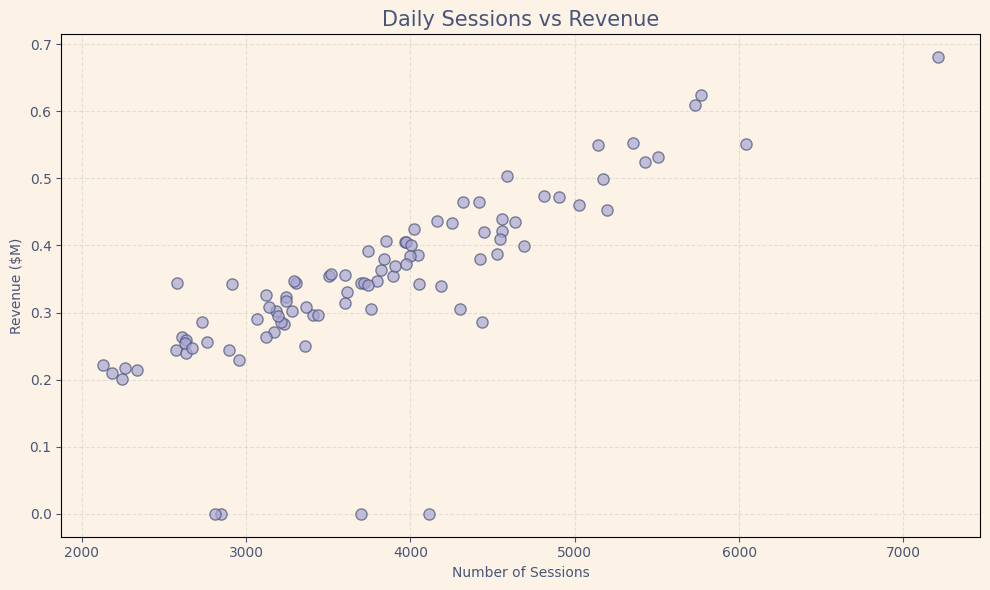

In [ ]:
BG_COLOR = "#FCF3E6"
LAVENDER = "#A9A5D3"
DARK_BLUE = "#485579"

fig, ax = plt.subplots(figsize=(10, 6))

fig.patch.set_facecolor(BG_COLOR)
ax.set_facecolor(BG_COLOR)

ax.scatter(
    daily_data['Sessions'],
    daily_data['Revenue'] / 1_000_000,
    color=LAVENDER,
    edgecolor=DARK_BLUE,
    alpha=0.7,
    s=65
)

ax.set_title(
    "Daily Sessions vs Revenue",
    fontsize=15,
    color=DARK_BLUE
)

ax.set_xlabel("Number of Sessions", color=DARK_BLUE)
ax.set_ylabel("Revenue ($M)", color=DARK_BLUE)

ax.grid(linestyle="--", alpha=0.3)
ax.tick_params(colors=DARK_BLUE)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [ ]:
#Розрахуємо кореляцію та перевіримо її значущість

# Виключаємо дні, коли сесії є, але дохід дорівнює 0
correlation_data = daily_data[
    daily_data['Revenue'] > 0
].copy()

# Кореляція Пірсона
pearson_corr, pearson_p = pearsonr(
    correlation_data['Sessions'],
    correlation_data['Revenue']
)

# Кореляція Спірмена
spearman_corr, spearman_p = spearmanr(
    correlation_data['Sessions'],
    correlation_data['Revenue']
)

print(f"Pearson correlation: {pearson_corr:.3f}")
print(f"Pearson p-value: {pearson_p:.5g}")

print(f"Spearman correlation: {spearman_corr:.3f}")
print(f"Spearman p-value: {spearman_p:.5g}")

Pearson correlation: 0.931
Pearson p-value: 1.7395e-39
Spearman correlation: 0.904
Spearman p-value: 1.5382e-33


##Кореляція між континентами, каналами трафіку та категоріями товарів

In [ ]:


# Виключаємо дати з 28 по 31 січня
df_corr = df[
    df['session_date'] < '2021-01-28'
].copy()

BG_COLOR = "#FCF3E6"
LAVENDER = "#A9A5D3"
DARK_BLUE = "#485579"


def plot_correlation(df, group_column, title):

    # Групуємо дохід за датою та категорією
    pivot_data = df.pivot_table(
        index='session_date',
        columns=group_column,
        values='product_price',
        aggfunc='sum',
        fill_value=0
    )

    # Розраховуємо кореляцію
    corr_matrix = pivot_data.corr()

    # Будуємо heatmap
    plt.figure(figsize=(10, 7))
    sns.heatmap(
        corr_matrix,
        annot=True,
        cmap=custom_cmap,
        center=0,
        fmt='.2f',
        linewidths=0.5
    )

    plt.title(title, fontsize=15, color=DARK_BLUE)
    plt.tight_layout()
    plt.show()

    return corr_matrix

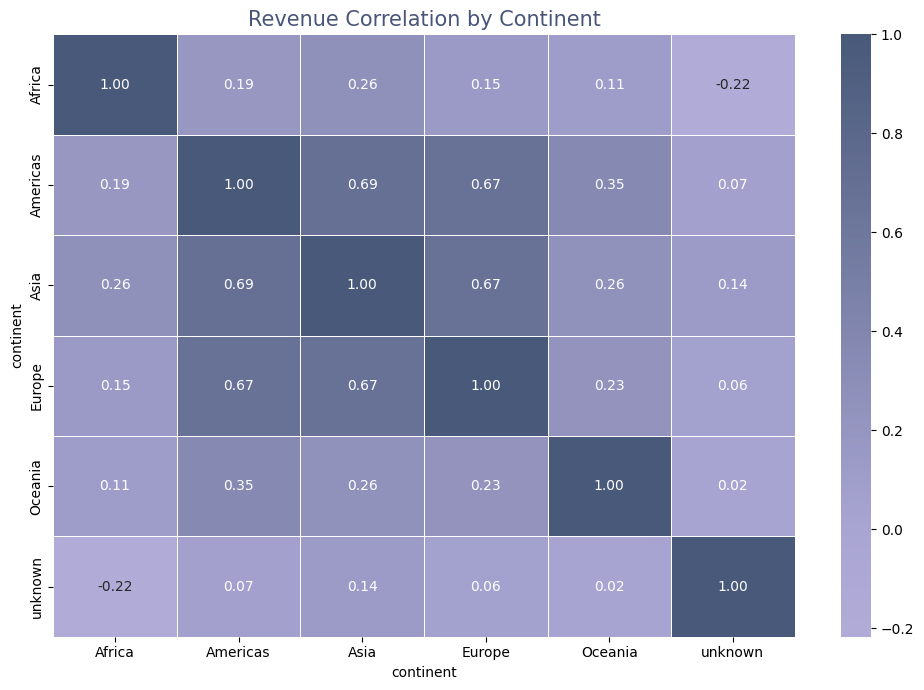

In [ ]:
#Кореляція між континентами

continent_corr = plot_correlation(
    df_corr,
    'continent',
    'Revenue Correlation by Continent'
)

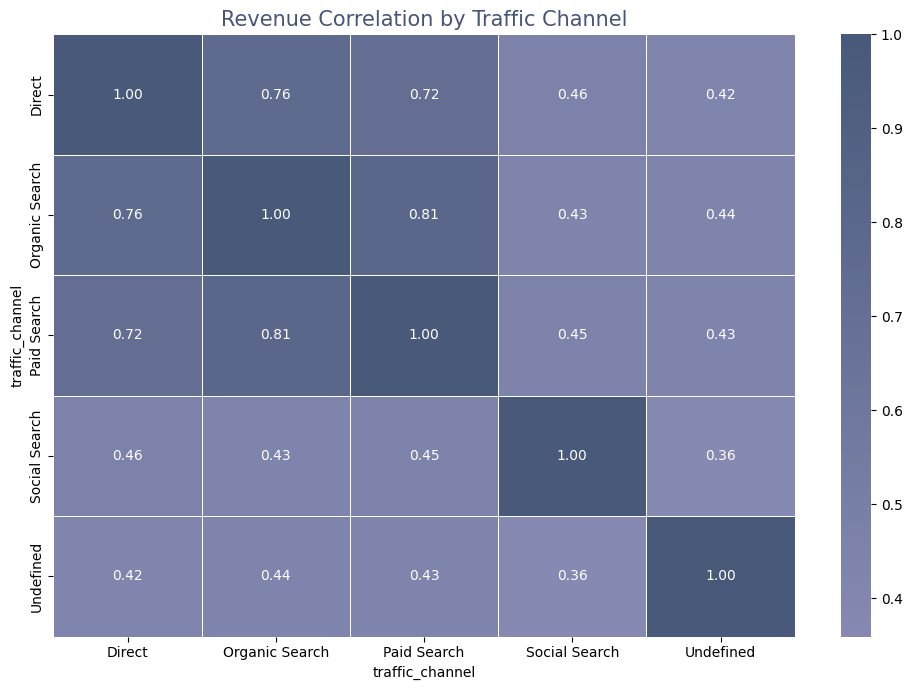

In [ ]:
#Кореляція між каналами трафіку

channel_corr = plot_correlation(
    df_corr,
    'traffic_channel',
    'Revenue Correlation by Traffic Channel'
)

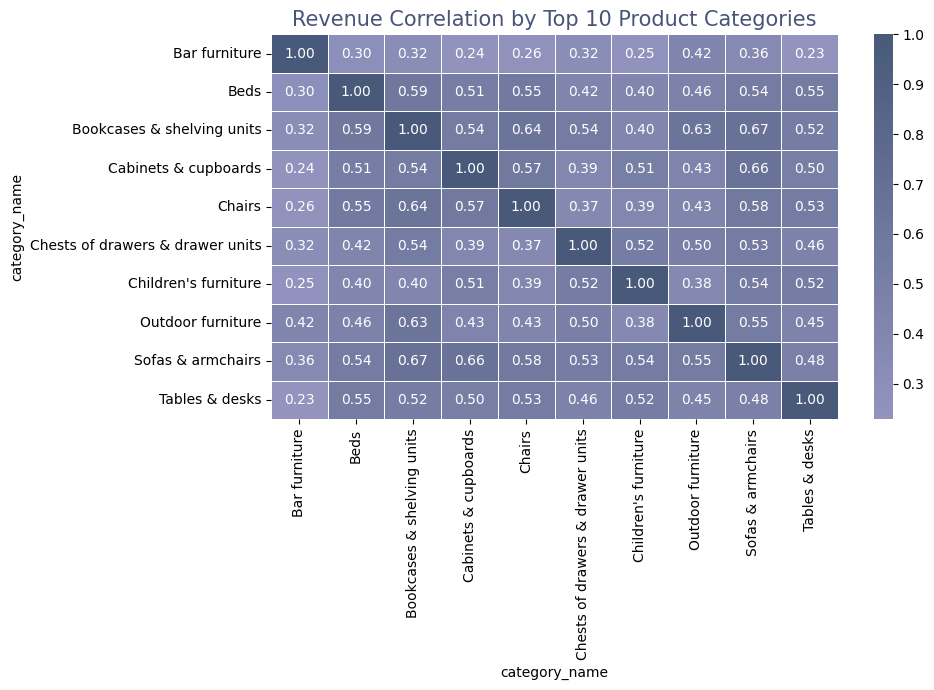

In [ ]:
#Кореляція між категоріями товарів

# Визначаємо 10 категорій з найбільшим доходом
top_categories = (
    df_corr.groupby('category_name')['product_price']
    .sum()
    .nlargest(10)
    .index
)

# Залишаємо тільки ці категорії
df_top_categories = df_corr[
    df_corr['category_name'].isin(top_categories)
]

category_corr = plot_correlation(
    df_top_categories,
    'category_name',
    'Revenue Correlation by Top 10 Product Categories'
)

### Висновок

Аналіз виявив **сильний позитивний зв'язок між кількістю сесій і доходом**. Коефіцієнт кореляції Пірсона становить 0,931, а Спірмена — 0,904. Обидва результати статистично значущі (p < 0,05).

Це означає, що зі збільшенням кількості сесій зазвичай зростає і дохід. Отже, залучення більшої кількості користувачів може сприяти збільшенню доходу компанії. Водночас кореляція не доводить прямого причинно-наслідкового зв'язку.

# Загальний бізнес-висновок

У межах дослідження було проаналізовано продажі та поведінку користувачів за різними напрямами: географією, товарними категоріями, каналами трафіку, пристроями й часовими періодами. Аналіз допомагає визначити основні джерела доходу, зрозуміти особливості активності користувачів і сформувати рекомендації для подальшого розвитку бізнесу.

## Основні результати

**1. Географічний розподіл продажів**

Найбільший обсяг продажів припадає на Америку — приблизно $17,67 млн. Далі йдуть Азія з $7,60 млн та Європа з $5,93 млн. Інші континенти формують значно меншу частину загального доходу.

Це свідчить про високу концентрацію продажів у кількох регіонах. Компанії варто підтримувати позиції на основних ринках і дослідити можливості розвитку в регіонах із нижчими обсягами продажів.

**2. Поведінка користувачів залежно від пристрою**

Комп'ютери забезпечують приблизно 58,5% усіх сесій, мобільні пристрої — 39,3%, а планшети — 2,2%.

Отже, основна активність користувачів припадає на комп'ютери та смартфони. Водночас значна частка мобільного трафіку робить зручність мобільної версії сайту важливим чинником користувацького досвіду.

**3. Динаміка активності користувачів**

Кількість сесій змінюється протягом досліджуваного періоду: спостерігаються періодичні піки та спади, але чіткого стабільного зростання не виявлено.

За днями тижня найбільша кількість унікальних сесій припадає на вівторок і середу, тоді як у вихідні активність нижча.

Ці закономірності можна використати для планування маркетингових кампаній, публікацій і спеціальних пропозицій.&#x20;

**4. Ефективність каналів трафіку**

Попередній аналіз показав, що Organic Search є одним із важливих джерел доходу та забезпечує приблизно $11,43 млн продажів.

Це робить органічний пошук перспективним напрямом для подальшого дослідження.&#x20;

**5. Зв'язок між активністю та доходом**

Аналіз виявив сильний позитивний зв'язок між кількістю сесій і доходом. Це означає, що періоди з більшою кількістю сесій зазвичай пов'язані з більшими обсягами продажів.

## Рекомендації для покращення бізнесу

**1. Посилити присутність на основних ринках**

- Проаналізувати, які товари та категорії приносять найбільший дохід в Америці, Азії та Європі.
- Адаптувати асортимент і маркетингові пропозиції до потреб користувачів у кожному регіоні.
- Оцінити потенціал країн із нижчими продажами, перш ніж збільшувати витрати на їхнє просування.

**2. Покращити мобільний користувацький досвід**

- Перевірити швидкість завантаження сторінок на смартфонах.
- Спрощувати процес оформлення покупки та навігацію.
- Порівняти конверсію, середній дохід і частоту відмов для комп'ютерів і мобільних пристроїв.

**3. Розвивати органічний пошук**

- Оптимізувати сторінки популярних товарів і категорій.
- Покращувати якість описів товарів та їхню відповідність пошуковим запитам.

**4. Планувати маркетингову активність на основі поведінки користувачів**

- Тестувати різний час запуску рекламних кампаній і спеціальних пропозицій.
- Порівнювати результати кампаній за доходом і конверсією, а не лише за кількістю сесій.

**5. Зосередитися на товарних категоріях із найбільшим потенціалом**

- Перевірити, чи не залежить загальний результат від невеликої кількості популярних товарів.
- Проаналізувати можливості збільшення середньої вартості покупки за допомогою комплектів товарів, рекомендацій супутніх продуктів і персоналізованих пропозицій.

##


# General Business Conclusions

In this project, I analysed sales and user behaviour in different areas: countries and continents, product categories, traffic channels, devices, and time periods. The analysis helps us understand where the main income comes from, how users behave, and how the business can improve.

## Main Results

**1. Sales by Continent**

The highest sales come from the Americas, with about 17.67 million. Asia is in second place, with 7.60 million, followed by Europe, with 5.93 million. Other continents bring much less income.

This means that most sales come from a few regions. The company should keep its strong position in these markets and look for new opportunities in regions with lower sales.

**2. User Behaviour by Device**

Desktop devices account for about 58.5% of all sessions, mobile devices account for 39.3%, and tablets account for 2.2%.

This means that most users visit the website on computers and smartphones. However, mobile traffic is also important, so the company should make sure that the website works well on mobile devices.

**3. Changes in User Activity**

The number of sessions changes during the period. There are some increases and decreases, but there is no clear and stable growth.

Tuesday and Wednesday have the highest number of unique sessions, while user activity is lower at weekends.

The company can use this information to plan marketing campaigns, posts, and special offers.

**4. Traffic Channel Performance**

The first analysis showed that Organic Search is an important source of income and brings about $11.43 million in sales.

This makes organic search an important area for further development and research.

**5. The Relationship Between Sessions and Income**

The analysis showed a strong positive relationship between the number of sessions and income. This means that periods with more sessions usually also have higher sales.

## Recommendations for Business Improvement

**1. Strengthen the Company's Position in Main Markets**

- Analyse which products and categories bring the most income in the Americas, Asia, and Europe.
- Choose products and marketing offers that meet the needs of users in each region.
- Study countries with lower sales before spending more money on promotion there.

**2. Improve the Mobile User Experience**

- Check how quickly pages load on smartphones.
- Make the buying process and website navigation easier.
- Compare conversion rates, average income, and bounce rates for desktop and mobile users.

**3. Develop Organic Search**

- Improve the pages of popular products and categories.
- Write better product descriptions and make sure they match what people search for online.

**4. Plan Marketing Activities Based on User Behaviour**

- Test different times for launching marketing campaigns and special offers.
- Compare campaign results by income and conversion rate, not only by the number of sessions.

**5. Focus on Product Categories with the Highest Potential**

- Check if total sales depend too much on a small number of popular products.
- Find ways to increase the average order value by offering product bundles, related products, and personal offers.

#Посилання на інтерактивний дашборд

https://public.tableau.com/app/profile/.32455230/viz/PortfolioProject1_17934490130200/SalesUserBehaviorDashboard?publish=yes